# Лабораторна робота № 7. Амплітудні перетворення, еквалізація гістограм та бінаризація методом Оцу

### Мета: Дослідити фундаментальні алгоритми поелементної амплітудної корекції монохромних цифрових зображень, опанувати математичні методи розрахунку та аналізу гістограм яскравості, реалізувати лінійне контрастування та нелінійну гамма-корекцію з використанням таблиць пошуку (LUT), засвоїти алгоритм глобальної еквалізації гістограм для розширення динамічного діапазону, а також порівняти ефективність глобальної порогової обробки, автоматичного методу міжкласової дисперсії Оцу та локальної адаптивної бінаризації на зображеннях із нерівномірним освітленням.

#### *Варіант 2 (№ 22 у списку: $22 - 20 = 2$)*

### <div align="right">Виконав: Яцентюк Євгеній, група: КІ-24-1</div>
<div align="right">
  <a href="https://github.com/kefir4ikk"><b>GitHub</b></a>
</div>

## 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import csv
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#2b2b2b'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

import matplotlib
print(f"NumPy: {np.__version__} | OpenCV: {cv2.__version__} | Pillow: {Image.__version__} | Matplotlib: {matplotlib.__version__}")

NumPy: 2.5.4 | OpenCV: 5.0.0 | Pillow: 13.0.0 | Matplotlib: 3.11.2


## 2. Параметри варіанта 2 та постановка завдання

**Індивідуальне завдання (варіант 2):**

| Тип зображення | $k,\ b$ | $\gamma_1,\ \gamma_2$ | $T_{fixed}$ | $S\times S,\ C$ |
|:-:|:-:|:-:|:-:|:-:|
| Магнітно-резонансна томограма мозку | $k=1.8,\ b=-40$ | $\gamma_1=0.40,\ \gamma_2=2.5$ | 95 | $S=15,\ C=4$ |

**Тестове зображення.** Для заданого типу синтезується аксіальний зріз **T1-зваженого МР-фантома голови** $400\times600$ (8 біт) з низьким контрастом (вікно яскравості $[35,\,170]$ замість повного діапазону), шумом сенсора $\sigma=3$ та **неоднорідністю чутливості** (bias field) — множником $B(x)=0.35+0.65\,x/(W-1)$, який змінює яскравість тканин зліва направо майже втричі (в еталонному прикладі лабораторної градієнт тла $40\to140$ — у 3.5 раза). Склад фантома (відносні яскравості до множення на $B$): повітря $0.03$; скальп $0.80$; кістка черепа $0.10$; ліквор $0.15$; сіра речовина $0.55$; біла речовина $0.80$; шлуночки $0.15$ (ліквор); гіпоінтенсивні вогнища в білій речовині $0.45$; борозни кори — тонкі (3 px) криві ліквору. Яскравість у 8-бітній шкалі: $I=35+125\cdot v\cdot B(x)+\nu$.

**Об'єкт бінаризації.** Цільові структури — темні: шлуночки, вогнища та борозни (ліквор у T1 темний). Тому для всіх методів застосовується **інверсна** бінаризація (`THRESH_BINARY_INV`: піксель вважається об'єктом, якщо $r\le T$), що відповідає призначенню адаптивного порога з $C>0$: поріг $\text{LocalMean}-C$ розташований нижче локального середнього, тобто виділяє ознаки, темніші за локальне тло. Оцінка виконується всередині ROI (внутрішня область мозку, без повітря, черепа та скальпа) з виключенням смуги $\pm1$ px навколо меж еталонної маски (розмиті краї); у фантомі еталонна маска відома точно: окремо тонкі структури (борозни) та великі (шлуночки, вогнища).

**Формули:**

$$s=\mathrm{clip}(k\,r+b,0,255);\qquad s=255\Big(\frac r{255}\Big)^{\gamma};\qquad s_k=\frac{\mathrm{CDF}(r_k)-\mathrm{CDF}_{min}}{MN-\mathrm{CDF}_{min}}\cdot255;\qquad \sigma_B^2(T)=\omega_0\omega_1(\mu_0-\mu_1)^2,$$

$$T_{adapt}(x,y)=\mathrm{LocalMean}_{S\times S}(x,y)-C.$$

Для лінійного перетворення $s=1.8r-40$: насичення в нуль при $r<22.2$ та в 255 при $r>163.9$; пряма $s=r$ перетинається в точці $r=50$. Для гамми: $\gamma_1=0.40$ висвітлює тіні ($r=100\to s=175$), $\gamma_2=2.5$ затемнює ($r=100\to s=24.5$).

In [2]:
# --- Параметри варіанта 2
K_CONTRAST, B_BRIGHT = 1.8, -40.0
GAMMA_BRIGHT, GAMMA_DARK = 0.40, 2.5
T_FIXED = 95
BLOCK_S, C_CONST = 15, 4
H_IMG, W_IMG = 400, 600

def generate_brain_mri_phantom(height=H_IMG, width=W_IMG, seed=42):
    """Синтетичний T1-фантом голови з низьким контрастом, bias field, шумом та еталонними масками."""
    rng = np.random.default_rng(seed)
    cx, cy = 300, 200
    v = np.full((height, width), 0.03, np.float32)                       # повітря
    for axes, val in [((215, 175), 0.80), ((205, 165), 0.10), ((196, 156), 0.15), ((190, 150), 0.55), ((148, 110), 0.80)]:
        cv2.ellipse(v, (cx, cy), axes, 0, 0, 360, val, -1)               # скальп, череп, ліквор, сіра, біла речовина
    brain = np.zeros((height, width), np.uint8); cv2.ellipse(brain, (cx, cy), (190, 150), 0, 0, 360, 255, -1)
    roi = cv2.erode(brain, np.ones((7, 7), np.uint8))                    # ROI: внутрішність мозку (відступ 3 px)

    vent = np.zeros((height, width), np.uint8)                           # шлуночки
    cv2.ellipse(vent, (268, 190), (34, 15), 12, 0, 360, 255, -1)
    cv2.ellipse(vent, (332, 190), (34, 15), -12, 0, 360, 255, -1)
    cv2.ellipse(vent, (300, 200), (6, 24), 0, 0, 360, 255, -1)
    vent_far = cv2.dilate(vent, np.ones((31, 31), np.uint8))

    lesion = np.zeros((height, width), np.uint8); placed = []           # гіпоінтенсивні вогнища
    for _ in range(600):
        if len(placed) == 6:
            break
        px, py, r = rng.uniform(cx - 125, cx + 125), rng.uniform(cy - 85, cy + 85), int(rng.integers(7, 14))
        if ((px - cx) / (148 - r - 6)) ** 2 + ((py - cy) / (110 - r - 6)) ** 2 > 1 or vent_far[int(py), int(px)] > 0:
            continue
        if any(np.hypot(px - qx, py - qy) < r + qr + 10 for qx, qy, qr in placed):
            continue
        cv2.circle(lesion, (int(px), int(py)), r, 255, -1); placed.append((px, py, r))

    sulci = np.zeros((height, width), np.uint8)                          # борозни: тонкі (3 px) криві ліквору
    for _ in range(26):
        th = rng.uniform(0, 2 * np.pi)
        p = np.array([cx + 188 * np.cos(th), cy + 148 * np.sin(th)])
        d = np.array([cx, cy]) - p; d /= np.linalg.norm(d)
        pts, length = [p.copy()], rng.uniform(28, 48)
        for _ in range(5):
            d = d + rng.normal(0, 0.35, 2); d /= np.linalg.norm(d)
            p = p + d * length / 5; pts.append(p.copy())
        cv2.polylines(sulci, [np.round(pts).astype(np.int32)], False, 255, 3)
    sulci = cv2.bitwise_and(sulci, brain)

    v[sulci > 0] = 0.15; v[vent > 0] = 0.15; v[lesion > 0] = 0.45
    v = cv2.GaussianBlur(v, (0, 0), 0.8)                                 # м'які краї
    bias = (0.35 + 0.65 * np.linspace(0, 1, width, dtype=np.float32))[None, :]
    img = 35 + 125 * v * bias + rng.normal(0, 3.0, (height, width))
    img = np.clip(np.rint(img), 0, 255).astype(np.uint8)
    masks = dict(brain=brain, roi=roi, vent=vent, lesion=lesion, sulci=sulci)
    return img, masks

img_raw, M = generate_brain_mri_phantom()
assert cv2.imwrite("data/low_contrast_input.png", img_raw)

roi = M['roi'] > 0
gt_thin = (M['sulci'] > 0) & roi & ~((M['vent'] > 0) | (M['lesion'] > 0))
gt_large = ((M['vent'] > 0) | (M['lesion'] > 0)) & roi
gt_all = gt_thin | gt_large
dc = cv2.subtract(cv2.dilate(gt_all.astype(np.uint8), np.ones((3, 3), np.uint8)), cv2.erode(gt_all.astype(np.uint8), np.ones((3, 3), np.uint8))) > 0
valid = roi & ~dc                                                         # область оцінювання
print(f"Фантом збережено: data/low_contrast_input.png ({H_IMG}x{W_IMG}, {img_raw.dtype})")
print(f"ROI: {int(roi.sum())} px; еталон: тонкі структури (борозни) {int(gt_thin.sum())} px, великі (шлуночки, вогнища) {int(gt_large.sum())} px; "
      f"частка цілі в ROI {100 * gt_all.sum() / roi.sum():.1f} %; вогнищ: {int(cv2.connectedComponents(M['lesion'])[0] - 1)}")

Фантом збережено: data/low_contrast_input.png (400x600, uint8)
ROI: 85835 px; еталон: тонкі структури (борозни) 4496 px, великі (шлуночки, вогнища) 5591 px; частка цілі в ROI 11.8 %; вогнищ: 6


## 3. Гістограмний аналіз вихідного зображення

Розраховуються ненормована гістограма $h(r_k)=n_k$ (`cv2.calcHist`), нормована $p(r_k)=n_k/(MN)$ та кумулятивна функція розподілу $\mathrm{CDF}(r_k)=\sum_{j\le k}p(r_j)$ (`np.histogram`). Статистичні характеристики: діапазон, динамічний розмах, середнє, СКВ та ентропія Шеннона $H=-\sum p_k\log_2p_k$. Збіг двох реалізацій гістограми перевіряється.

СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ ЯСКРАВОСТІ ВХІДНОГО ЗОБРАЖЕННЯ
Діапазон яскравості:       [24, 133] (динамічний розмах 109 рівнів із 255)
Середня яскравість (Mean): 60.48 / 255
Стандартне відхилення:     28.22
Ентропія Шеннона:          5.853 біт/піксель (зайнято 110 з 256 рівнів)
Фон (повітря): частка кадру 46.6 %, середня яскравість 37.5, СКВ шуму 3.15
Мода гістограми: рівень 38 (6.47 % пікселів); CDF(мода) = 0.313


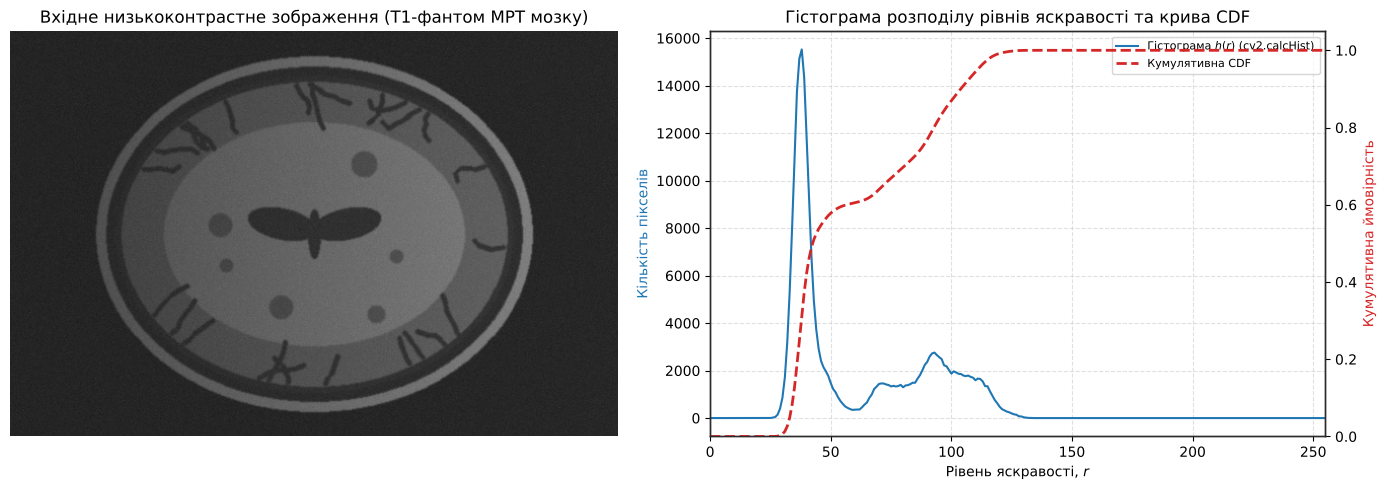

In [3]:
hist_cv = cv2.calcHist([img_raw], [0], None, [256], [0, 256]).ravel()
pdf_np, _ = np.histogram(img_raw.ravel(), bins=256, range=(0, 256), density=True)
cdf_np = np.cumsum(pdf_np); cdf_normalized = cdf_np / cdf_np[-1]
p_norm = hist_cv / hist_cv.sum()
assert np.array_equal(hist_cv.astype(int), np.bincount(img_raw.ravel(), minlength=256))      # cv2.calcHist = лічильник рівнів
assert np.allclose(p_norm, pdf_np)                                                              # p(r_k) = n_k/(MN)

def image_stats(im):
    p = np.bincount(im.ravel(), minlength=256) / im.size
    nz = p[p > 0]
    return dict(min=int(im.min()), max=int(im.max()), range=int(im.max()) - int(im.min()), mean=float(im.mean()), std=float(im.std()),
                entropy=float(-np.sum(nz * np.log2(nz))), levels=int(np.count_nonzero(p)))

st_raw = image_stats(img_raw)
head_big = cv2.dilate(cv2.ellipse(np.zeros((H_IMG, W_IMG), np.uint8), (300, 200), (215, 175), 0, 0, 360, 255, -1), np.ones((13, 13), np.uint8)) > 0
air_bg = ~head_big                                                                              # повітря поза головою (з відступом)
print("=" * 82)
print("СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ ЯСКРАВОСТІ ВХІДНОГО ЗОБРАЖЕННЯ")
print("=" * 82)
print(f"Діапазон яскравості:       [{st_raw['min']}, {st_raw['max']}] (динамічний розмах {st_raw['range']} рівнів із 255)")
print(f"Середня яскравість (Mean): {st_raw['mean']:.2f} / 255")
print(f"Стандартне відхилення:     {st_raw['std']:.2f}")
print(f"Ентропія Шеннона:          {st_raw['entropy']:.3f} біт/піксель (зайнято {st_raw['levels']} з 256 рівнів)")
print(f"Фон (повітря): частка кадру {100 * air_bg.mean():.1f} %, середня яскравість {img_raw[air_bg].mean():.1f}, СКВ шуму {img_raw[air_bg].std():.2f}")
mode_level = int(np.argmax(hist_cv))
print(f"Мода гістограми: рівень {mode_level} ({100 * hist_cv[mode_level] / img_raw.size:.2f} % пікселів); CDF(мода) = {cdf_normalized[mode_level]:.3f}")
print("=" * 82)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(img_raw, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Вхідне низькоконтрастне зображення (T1-фантом МРТ мозку)"); axes[0].axis('off')
axes[1].plot(hist_cv, color='#1f77b4', lw=1.5, label='Гістограма $h(r)$ (cv2.calcHist)')
axes[1].set_xlabel("Рівень яскравості, $r$"); axes[1].set_ylabel("Кількість пікселів", color='#1f77b4')
axes[1].set_xlim([0, 255]); axes[1].grid(True)
ax_cdf = axes[1].twinx()
ax_cdf.plot(cdf_normalized, color='#d62728', lw=2.0, linestyle='--', label='Кумулятивна CDF')
ax_cdf.set_ylabel("Кумулятивна ймовірність", color='#d62728'); ax_cdf.set_ylim([0, 1.05])
axes[1].set_title("Гістограма розподілу рівнів яскравості та крива CDF")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax_cdf.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig("figures/histogram_analysis.png", dpi=200)
plt.show()

## 4. Лінійне контрастування та гамма-корекція через таблиці пошуку (LUT)

Таблиці з 256 елементів формуються один раз, `cv2.LUT` застосовує їх до всіх пікселів (складність $O(MN)$ зі стрімким індексуванням замість $MN$ викликів степеневої функції). Значення округлюються до найближчого цілого (`np.rint`). Результат верифікується прямим поелементним обчисленням. Додатково визначається частка насичених пікселів (0 або 255) — ціна лінійного розтягування.

Лінійна: s = 1.8·r -40; насичення: s = 0 при r < 22.2, s = 255 при r > 163.9; насичених пікселів: 0.00 % (нуль), 0.00 % (255)
Гамма 0.4: r = 50 -> 133, r = 100 -> 175, r = 150 -> 206;  гамма 2.5: r = 50 -> 4, r = 100 -> 25, r = 150 -> 68


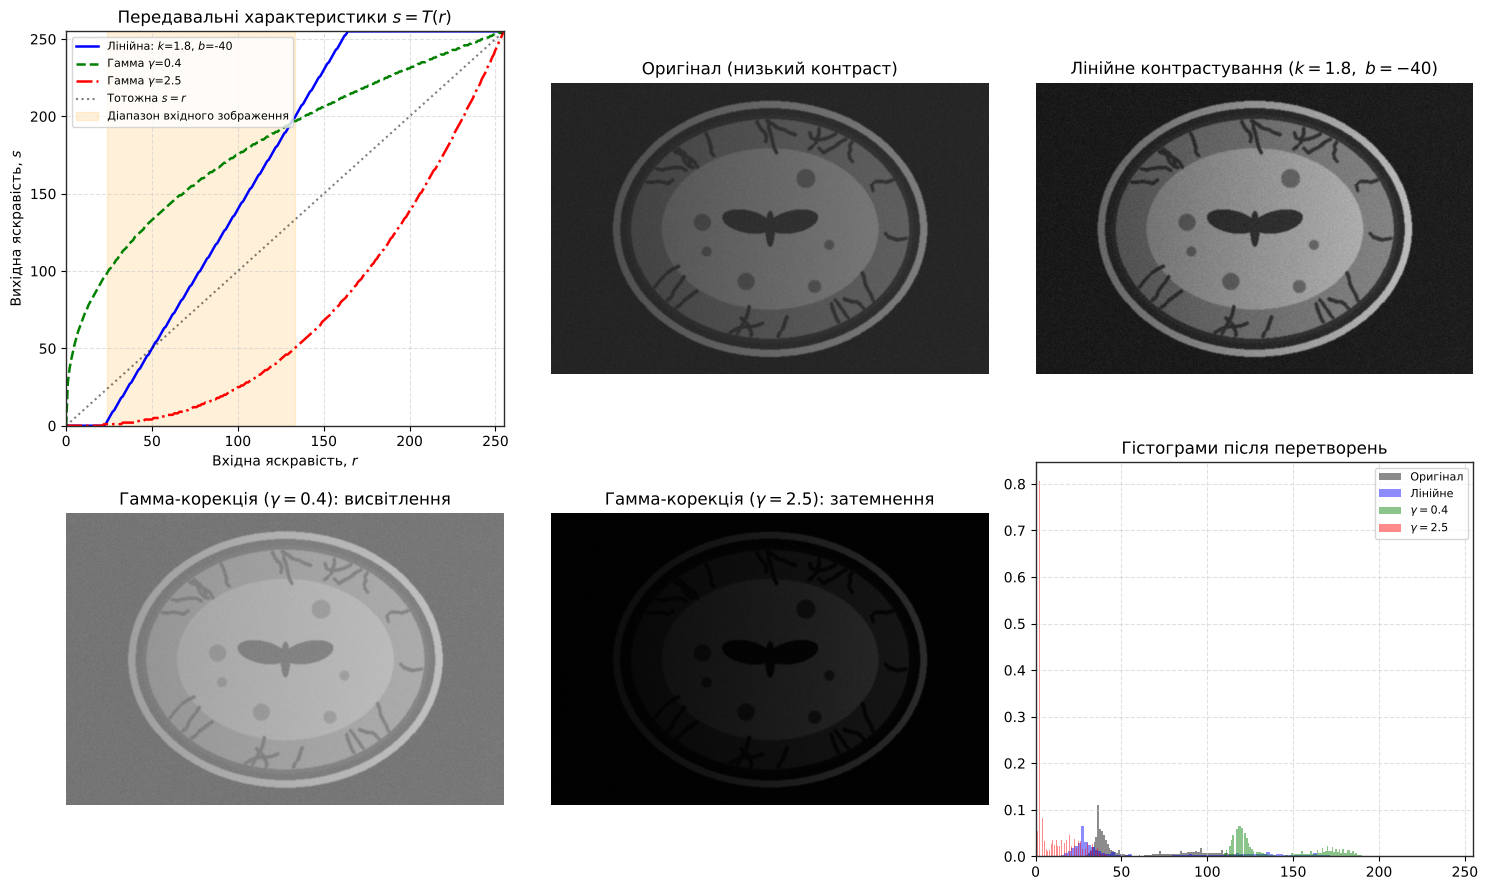

In [4]:
r_scale = np.arange(256, dtype=np.float64)
lut_linear = np.clip(np.rint(K_CONTRAST * r_scale + B_BRIGHT), 0, 255).astype(np.uint8)
lut_gamma_b = np.clip(np.rint(255.0 * (r_scale / 255.0) ** GAMMA_BRIGHT), 0, 255).astype(np.uint8)
lut_gamma_d = np.clip(np.rint(255.0 * (r_scale / 255.0) ** GAMMA_DARK), 0, 255).astype(np.uint8)

img_linear = cv2.LUT(img_raw, lut_linear)
img_gamma_b = cv2.LUT(img_raw, lut_gamma_b)
img_gamma_d = cv2.LUT(img_raw, lut_gamma_d)

# Верифікація: LUT = пряме обчислення для кожного пікселя
manual_linear = np.clip(np.rint(K_CONTRAST * img_raw.astype(np.float64) + B_BRIGHT), 0, 255).astype(np.uint8)
manual_gamma_b = np.clip(np.rint(255.0 * (img_raw / 255.0) ** GAMMA_BRIGHT), 0, 255).astype(np.uint8)
assert np.array_equal(img_linear, manual_linear) and np.array_equal(img_gamma_b, manual_gamma_b)

sat_lo = 100 * np.mean(img_linear == 0); sat_hi = 100 * np.mean(img_linear == 255)
r_zero, r_full = (0 - B_BRIGHT) / K_CONTRAST, (255 - B_BRIGHT) / K_CONTRAST
print(f"Лінійна: s = {K_CONTRAST}·r {B_BRIGHT:+.0f}; насичення: s = 0 при r < {r_zero:.1f}, s = 255 при r > {r_full:.1f}; "
      f"насичених пікселів: {sat_lo:.2f} % (нуль), {sat_hi:.2f} % (255)")
print(f"Гамма {GAMMA_BRIGHT}: r = 50 -> {lut_gamma_b[50]}, r = 100 -> {lut_gamma_b[100]}, r = 150 -> {lut_gamma_b[150]};  "
      f"гамма {GAMMA_DARK}: r = 50 -> {lut_gamma_d[50]}, r = 100 -> {lut_gamma_d[100]}, r = 150 -> {lut_gamma_d[150]}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].plot(r_scale, lut_linear, 'b-', lw=1.8, label=f'Лінійна: $k$={K_CONTRAST}, $b$={B_BRIGHT:.0f}')
axes[0, 0].plot(r_scale, lut_gamma_b, 'g--', lw=1.8, label=f'Гамма $\\gamma$={GAMMA_BRIGHT}')
axes[0, 0].plot(r_scale, lut_gamma_d, 'r-.', lw=1.8, label=f'Гамма $\\gamma$={GAMMA_DARK}')
axes[0, 0].plot(r_scale, r_scale, 'k:', alpha=0.5, label='Тотожна $s=r$')
axes[0, 0].axvspan(st_raw['min'], st_raw['max'], color='orange', alpha=0.15, label='Діапазон вхідного зображення')
axes[0, 0].set_title("Передавальні характеристики $s = T(r)$"); axes[0, 0].set_xlabel("Вхідна яскравість, $r$"); axes[0, 0].set_ylabel("Вихідна яскравість, $s$")
axes[0, 0].set_xlim([0, 255]); axes[0, 0].set_ylim([0, 255]); axes[0, 0].grid(True); axes[0, 0].legend(fontsize=8)
for ax, im, ttl in [(axes[0, 1], img_raw, "Оригінал (низький контраст)"),
                    (axes[0, 2], img_linear, f"Лінійне контрастування ($k={K_CONTRAST},\\ b={B_BRIGHT:.0f}$)"),
                    (axes[1, 0], img_gamma_b, f"Гамма-корекція ($\\gamma={GAMMA_BRIGHT}$): висвітлення"),
                    (axes[1, 1], img_gamma_d, f"Гамма-корекція ($\\gamma={GAMMA_DARK}$): затемнення")]:
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(ttl); ax.axis('off')
for im, col, lab in [(img_raw, 'k', 'Оригінал'), (img_linear, 'b', 'Лінійне'), (img_gamma_b, 'g', f'$\\gamma={GAMMA_BRIGHT}$'), (img_gamma_d, 'r', f'$\\gamma={GAMMA_DARK}$')]:
    axes[1, 2].hist(im.ravel(), bins=100, color=col, alpha=0.45, density=True, label=lab)
axes[1, 2].set_title("Гістограми після перетворень"); axes[1, 2].set_xlim([0, 255]); axes[1, 2].grid(True); axes[1, 2].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/linear_and_gamma_transf.png", dpi=200)
plt.show()

## 5. Глобальна еквалізація гістограми (OpenCV, Pillow та ручна реалізація)

Еквалізація виконується `cv2.equalizeHist` та `PIL.ImageOps.equalize`; крім того, реалізовано ручний розрахунок за CDF у двох формах: формула лабораторної $s_k=255\,\mathrm{CDF}(r_k)$ та нормування OpenCV з відніманням $\mathrm{CDF}_{min}$. Це дозволяє з'ясувати, чому OpenCV та Pillow не обов'язково дають однаковий результат. Додатково оцінюється вплив на фон: оскільки повітря займає значну частку кадру, воно має великий внесок у CDF.

ОЦІНКА РЕЗУЛЬТАТІВ ГЛОБАЛЬНОЇ ЕКВАЛІЗАЦІЇ ГІСТОГРАМИ
                                                  до    після (OpenCV)
Динамічний розмах, рівнів                        109               255
Середня яскравість                             60.48            131.08
СКВ (контраст)                                 28.22             71.50
Ентропія, біт                                  5.853             5.805
Зайнято рівнів                                   110                88
Середнє відхилення CDF від прямої             0.3781            0.0017
Фон (повітря): середня яскравість               37.5              70.8
Фон (повітря): СКВ шуму                         3.15             38.35   (підсилення ×12.2)
Біла речовина: середня яскравість              102.6             225.7
Довідково, CLAHE (clip 2.0, 8x8): СКВ / СКВ шуму фону       38.36              8.99
--------------------------------------------------------------------------------------
Порівняння реалізацій                       m

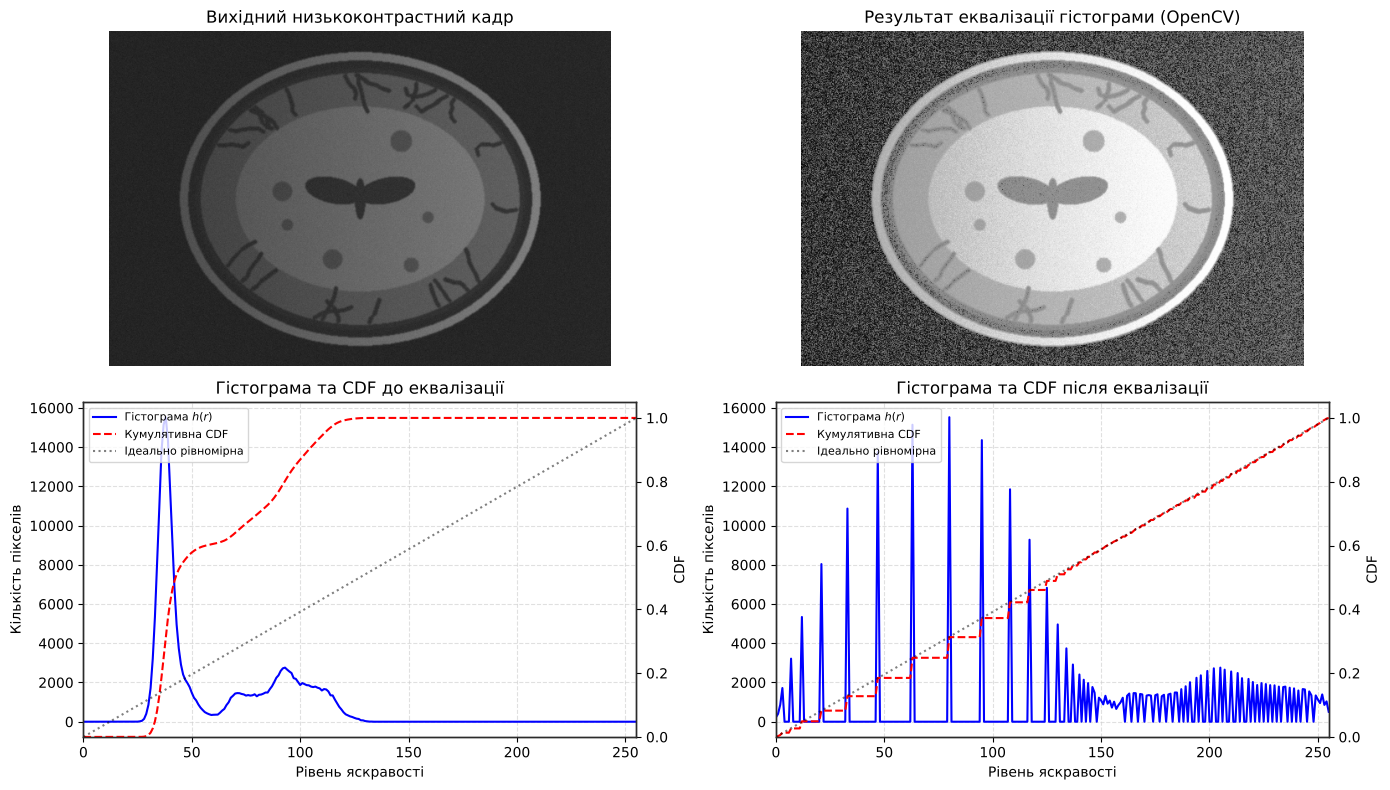

In [5]:
def equalize_manual(im, mode):
    h = np.bincount(im.ravel(), minlength=256); cdf = np.cumsum(h); N_ = im.size
    if mode == "lab":                         # s_k = (L-1) * CDF(r_k)
        lut = np.rint(255.0 * cdf / N_)
    elif mode == "opencv":                    # нормування з відніманням CDF_min (як у cv2.equalizeHist)
        cmin = cdf[cdf > 0][0]
        lut = np.rint(255.0 * (cdf - cmin) / (N_ - cmin))
    elif mode == "pillow":                    # алгоритм ImageOps.equalize: крок = (N - h_last) // 255
        nz = h[h > 0]; step = (nz.sum() - nz[-1]) // 255
        lut = (np.cumsum(np.r_[0, h[:-1]]) + step // 2) // step
    return np.clip(lut, 0, 255).astype(np.uint8)[im]

img_eq_cv = cv2.equalizeHist(img_raw)
img_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img_raw)      # довідково: адаптивна еквалізація з обмеженням контрасту
img_eq_pil = np.array(ImageOps.equalize(Image.fromarray(img_raw)))
eq_lab, eq_ocv, eq_pil_m = (equalize_manual(img_raw, m) for m in ("lab", "opencv", "pillow"))
assert np.array_equal(eq_ocv, img_eq_cv)                  # ручна формула OpenCV збігається з cv2.equalizeHist
assert np.array_equal(eq_pil_m, img_eq_pil)               # ручна формула Pillow збігається з ImageOps.equalize

dif = lambda a, b: (int(np.max(np.abs(a.astype(int) - b.astype(int)))), float(np.mean(np.abs(a.astype(int) - b.astype(int)))), 100 * float(np.mean(a == b)))
d_cv_pil, d_cv_lab, d_pil_lab = dif(img_eq_cv, img_eq_pil), dif(img_eq_cv, eq_lab), dif(img_eq_pil, eq_lab)

hist_eq = np.bincount(img_eq_cv.ravel(), minlength=256)
cdf_eq = np.cumsum(hist_eq) / img_raw.size
st_eq = image_stats(img_eq_cv)
levels_occ = np.where(hist_eq > 0)[0]
cdf_dev = float(np.mean(np.abs(cdf_eq[levels_occ] - (levels_occ + 1) / 256.0)))
cdf_dev_raw = float(np.mean(np.abs(np.cumsum(hist_cv)[np.where(hist_cv > 0)[0]] / img_raw.size - (np.where(hist_cv > 0)[0] + 1) / 256.0)))

air_std_before, air_std_after = float(img_raw[air_bg].std()), float(img_eq_cv[air_bg].std())
air_mean_before, air_mean_after = float(img_raw[air_bg].mean()), float(img_eq_cv[air_bg].mean())
wm_zone = (M['roi'] > 0) & (cv2.erode(cv2.ellipse(np.zeros((H_IMG, W_IMG), np.uint8), (300, 200), (130, 95), 0, 0, 360, 255, -1), np.ones((9, 9), np.uint8)) > 0) & ~(gt_all | dc)

print("=" * 86)
print("ОЦІНКА РЕЗУЛЬТАТІВ ГЛОБАЛЬНОЇ ЕКВАЛІЗАЦІЇ ГІСТОГРАМИ")
print("=" * 86)
print(f"{'':<40}{'до':>12}{'після (OpenCV)':>18}")
print(f"{'Динамічний розмах, рівнів':<40}{st_raw['range']:12d}{st_eq['range']:18d}")
print(f"{'Середня яскравість':<40}{st_raw['mean']:12.2f}{st_eq['mean']:18.2f}")
print(f"{'СКВ (контраст)':<40}{st_raw['std']:12.2f}{st_eq['std']:18.2f}")
print(f"{'Ентропія, біт':<40}{st_raw['entropy']:12.3f}{st_eq['entropy']:18.3f}")
print(f"{'Зайнято рівнів':<40}{st_raw['levels']:12d}{st_eq['levels']:18d}")
print(f"{'Середнє відхилення CDF від прямої':<40}{cdf_dev_raw:12.4f}{cdf_dev:18.4f}")
print(f"{'Фон (повітря): середня яскравість':<40}{air_mean_before:12.1f}{air_mean_after:18.1f}")
print(f"{'Фон (повітря): СКВ шуму':<40}{air_std_before:12.2f}{air_std_after:18.2f}   (підсилення ×{air_std_after / air_std_before:.1f})")
print(f"{'Біла речовина: середня яскравість':<40}{img_raw[wm_zone].mean():12.1f}{img_eq_cv[wm_zone].mean():18.1f}")
st_clahe = image_stats(img_clahe)
print(f"{'Довідково, CLAHE (clip 2.0, 8x8): СКВ / СКВ шуму фону':<40}{st_clahe['std']:12.2f}{img_clahe[air_bg].std():18.2f}")
print("-" * 86)
print(f"{'Порівняння реалізацій':<40}{'max|Δ|':>10}{'середнє |Δ|':>14}{'збіг пікселів, %':>20}")
print(f"{'OpenCV проти Pillow':<40}{d_cv_pil[0]:10d}{d_cv_pil[1]:14.3f}{d_cv_pil[2]:20.2f}")
print(f"{'OpenCV проти формули s_k = 255·CDF':<40}{d_cv_lab[0]:10d}{d_cv_lab[1]:14.3f}{d_cv_lab[2]:20.2f}")
print(f"{'Pillow проти формули s_k = 255·CDF':<40}{d_pil_lab[0]:10d}{d_pil_lab[1]:14.3f}{d_pil_lab[2]:20.2f}")
print("=" * 86)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].imshow(img_raw, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title("Вихідний низькоконтрастний кадр"); axes[0, 0].axis('off')
axes[0, 1].imshow(img_eq_cv, cmap='gray', vmin=0, vmax=255); axes[0, 1].set_title("Результат еквалізації гістограми (OpenCV)"); axes[0, 1].axis('off')
for ax, hh, cc, ttl in [(axes[1, 0], hist_cv, cdf_normalized, "Гістограма та CDF до еквалізації"),
                        (axes[1, 1], hist_eq, cdf_eq, "Гістограма та CDF після еквалізації")]:
    ax.plot(hh, color='b', label='Гістограма $h(r)$'); ax.set_xlabel("Рівень яскравості"); ax.set_ylabel("Кількість пікселів"); ax.set_xlim([0, 255]); ax.grid(True)
    axc = ax.twinx(); axc.plot(np.arange(256), cc, color='r', ls='--', label='Кумулятивна CDF'); axc.plot([0, 255], [0, 1], 'k:', alpha=0.5, label='Ідеально рівномірна')
    axc.set_ylim([0, 1.05]); axc.set_ylabel("CDF")
    ax.set_title(ttl)
    ha, la = ax.get_legend_handles_labels(); hb, lb = axc.get_legend_handles_labels(); ax.legend(ha + hb, la + lb, loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig("figures/histogram_equalization.png", dpi=200)
plt.show()

## 6. Метод Оцу: ручна реалізація та порівняння з OpenCV

Для кожного порога $T$ розраховуються ваги класів $\omega_0(T)$, $\omega_1(T)$ та міжкласова дисперсія $\sigma_B^2(T)=\dfrac{(\mu_T\omega_0-\mu(T))^2}{\omega_0(1-\omega_0)}$, що еквівалентно $\omega_0\omega_1(\mu_0-\mu_1)^2$. Оптимальний поріг — максимум $\sigma_B^2(T)$; клас 0 містить рівні $r\le T$. Результат порівнюється з `cv2.threshold(..., THRESH_OTSU)`.

Поріг Оцу: ручна реалізація T = 67; cv2.threshold T = 67; max σ_B² = 694.4; загальна дисперсія σ_T² = 796.3; ефективність розділення η = σ_B²/σ_T² = 0.872


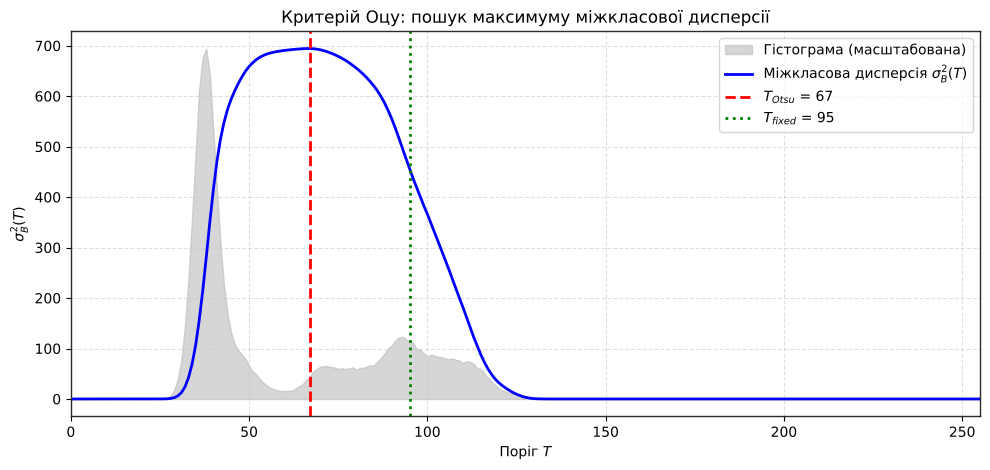

In [6]:
def otsu_manual(im):
    p = np.bincount(im.ravel(), minlength=256).astype(np.float64); p /= p.sum()
    w0 = np.cumsum(p); mu_cum = np.cumsum(np.arange(256) * p); mu_t = mu_cum[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sb2 = (mu_t * w0 - mu_cum) ** 2 / (w0 * (1.0 - w0))
    sb2 = np.nan_to_num(sb2)
    return int(np.argmax(sb2)), sb2

T_otsu_manual, sigma_b2 = otsu_manual(img_raw)
T_otsu_cv, _ = cv2.threshold(img_raw, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Поріг Оцу: ручна реалізація T = {T_otsu_manual}; cv2.threshold T = {T_otsu_cv:.0f}; max σ_B² = {sigma_b2.max():.1f}; "
      f"загальна дисперсія σ_T² = {img_raw.var():.1f}; ефективність розділення η = σ_B²/σ_T² = {sigma_b2.max() / img_raw.var():.3f}")
assert abs(T_otsu_manual - T_otsu_cv) <= 1

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(np.arange(256), hist_cv / hist_cv.max() * sigma_b2.max(), color='#bbbbbb', alpha=0.6, label='Гістограма (масштабована)')
ax.plot(sigma_b2, 'b-', lw=2, label=r'Міжкласова дисперсія $\sigma_B^2(T)$')
ax.axvline(T_otsu_cv, color='r', ls='--', lw=2, label=f'$T_{{Otsu}}$ = {T_otsu_cv:.0f}')
ax.axvline(T_FIXED, color='g', ls=':', lw=2, label=f'$T_{{fixed}}$ = {T_FIXED}')
ax.set_title("Критерій Оцу: пошук максимуму міжкласової дисперсії"); ax.set_xlabel("Поріг $T$"); ax.set_ylabel(r"$\sigma_B^2(T)$")
ax.set_xlim([0, 255]); ax.grid(True); ax.legend()
plt.tight_layout()
plt.savefig("figures/otsu_criterion.png", dpi=200)
plt.show()

## 7. Порівняння методів бінаризації на зображенні з нерівномірним освітленням

Для темних цільових структур (шлуночки, вогнища, борозни) застосовуються: фіксований поріг $T_{fixed}=95$, метод Оцу, адаптивні Mean та Gaussian ($S=15$, $C=4$), всі з `THRESH_BINARY_INV`. Метрики (в ROI, без смуги країв): точність (precision), повнота (recall), $F_1$, $F_1$ окремо для лівої (темнішої) та правої (світлішої) половин кадру, повнота для тонких структур (борозни) та великих (шлуночки, вогнища). Додатково перевіряються: варіант адаптивного Gaussian із попереднім гауссовим згладжуванням ($\sigma=1$) та залежність від розміру вікна $S$.

ПОРІВНЯННЯ МЕТОДІВ БІНАРИЗАЦІЇ (темні структури в ROI, THRESH_BINARY_INV)
Метод                                      precision  recall     F1  F1 ліво  F1 право  recall тонкі  recall великі  хибні на тлі, %
Фіксований T = 95                              0.155   1.000  0.268    0.217     0.354         1.000          1.000            51.29
Оцу (T = 67)                                   0.782   0.818  0.800    0.739     0.881         1.000          0.738             2.14
Adaptive Mean (S = 15, C = 4)                  0.373   0.732  0.494    0.499     0.490         0.996          0.616            11.56
Adaptive Gaussian (S = 15, C = 4)              0.318   0.568  0.408    0.406     0.410         0.947          0.401            11.45
Adaptive Gaussian + згладжування σ = 1         0.826   0.544  0.656    0.671     0.642         0.971          0.356             1.08

    S  precision  recall     F1  recall тонкі  recall великі  F1 ліво  F1 право  F1 +згладж.    F1 ліво/право +згладж.
    7   

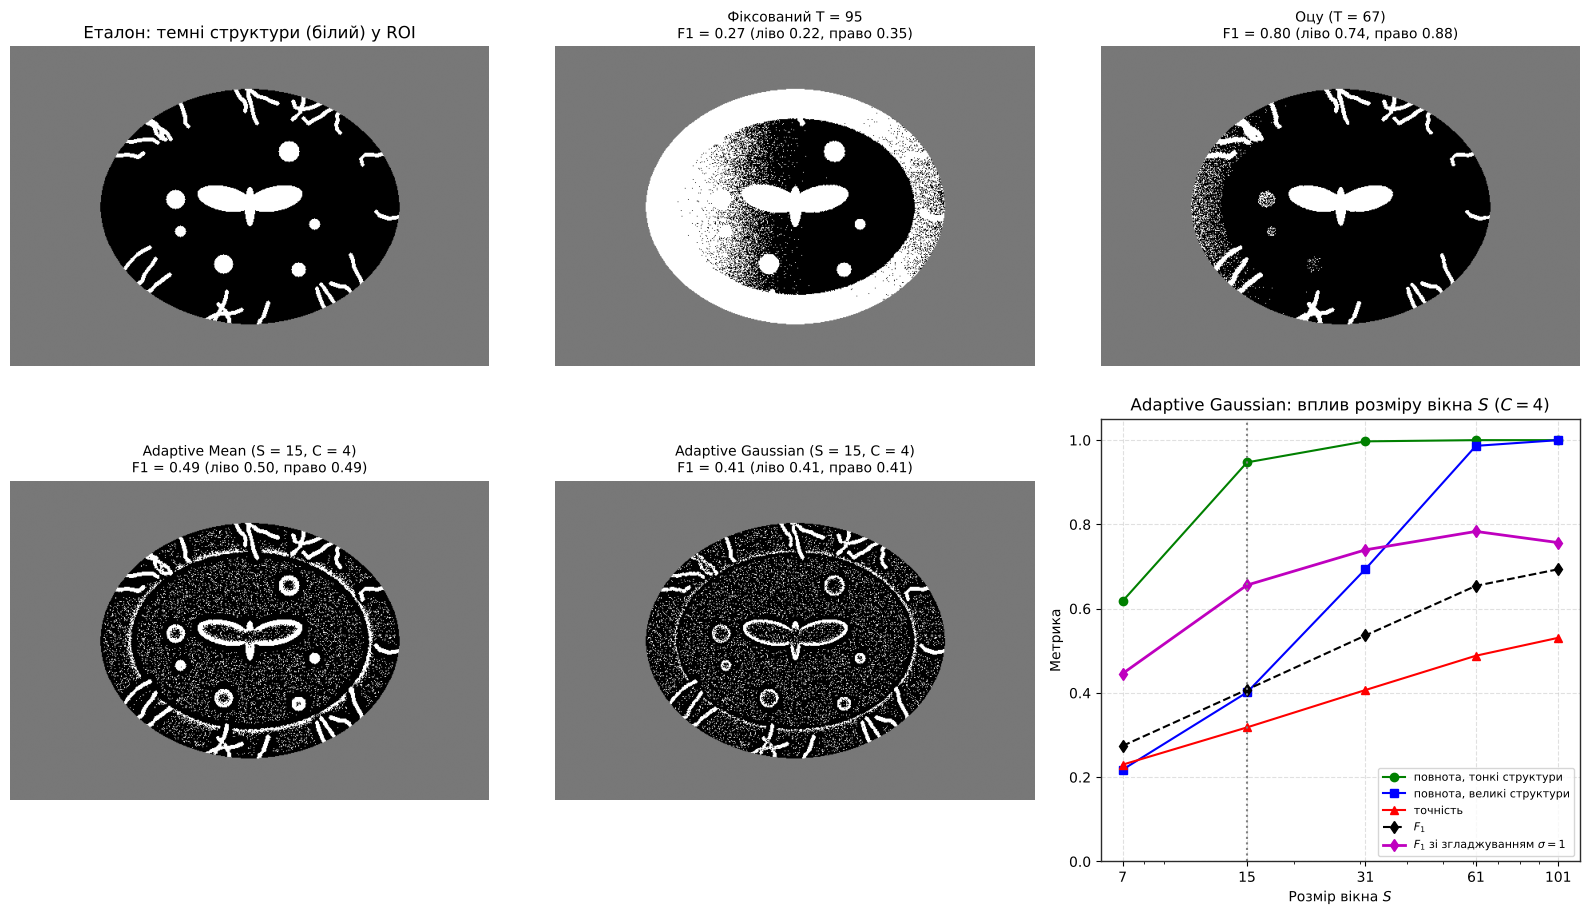

In [7]:
def binarize(img, method, S=BLOCK_S, C=C_CONST):
    if method == "fixed":   return cv2.threshold(img, T_FIXED, 255, cv2.THRESH_BINARY_INV)[1]
    if method == "otsu":    return cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    if method == "mean":    return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, S, C)
    if method == "gauss":   return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, S, C)
    if method == "gauss_pre": return cv2.adaptiveThreshold(cv2.GaussianBlur(img, (0, 0), 1.0), 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, S, C)

left_half = np.zeros((H_IMG, W_IMG), bool); left_half[:, :W_IMG // 2] = True

def prf(pred, gt, region):
    p, g = (pred > 0) & region, gt & region
    tp = np.sum(p & g); fp = np.sum(p & ~g); fn = np.sum(~p & g)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return float(prec), float(rec), float(2 * prec * rec / max(prec + rec, 1e-12))

def evaluate(pred):
    prec, rec, f1 = prf(pred, gt_all, valid)
    return dict(precision=prec, recall=rec, f1=f1,
                f1_left=prf(pred, gt_all, valid & left_half)[2], f1_right=prf(pred, gt_all, valid & ~left_half)[2],
                recall_thin=prf(pred, gt_thin, valid)[1], recall_large=prf(pred, gt_large, valid)[1],
                fp_flat_pct=100 * float(np.mean((pred > 0)[valid & ~gt_all])))

methods = [("fixed", f"Фіксований T = {T_FIXED}"), ("otsu", f"Оцу (T = {T_otsu_cv:.0f})"),
           ("mean", f"Adaptive Mean (S = {BLOCK_S}, C = {C_CONST})"), ("gauss", f"Adaptive Gaussian (S = {BLOCK_S}, C = {C_CONST})"),
           ("gauss_pre", "Adaptive Gaussian + згладжування σ = 1")]
preds = {key: binarize(img_raw, key) for key, _ in methods}
res = {key: evaluate(preds[key]) for key, _ in methods}

print("=" * 124)
print("ПОРІВНЯННЯ МЕТОДІВ БІНАРИЗАЦІЇ (темні структури в ROI, THRESH_BINARY_INV)")
print("=" * 124)
print(f"{'Метод':<42}{'precision':>10}{'recall':>8}{'F1':>7}{'F1 ліво':>9}{'F1 право':>10}{'recall тонкі':>14}{'recall великі':>15}{'хибні на тлі, %':>17}")
for key, name in methods:
    r_ = res[key]
    print(f"{name:<42}{r_['precision']:10.3f}{r_['recall']:8.3f}{r_['f1']:7.3f}{r_['f1_left']:9.3f}{r_['f1_right']:10.3f}{r_['recall_thin']:14.3f}{r_['recall_large']:15.3f}{r_['fp_flat_pct']:17.2f}")
print("=" * 124)

# --- Вплив розміру вікна S (Adaptive Gaussian, C = 4)
S_list = [7, 15, 31, 61, 101]
sweep = []
print(f"\n{'S':>5}{'precision':>11}{'recall':>8}{'F1':>7}{'recall тонкі':>14}{'recall великі':>15}{'F1 ліво':>9}{'F1 право':>10}{'F1 +згладж.':>13}{'F1 ліво/право +згладж.':>26}")
for S in S_list:
    e = evaluate(binarize(img_raw, "gauss", S=S)); ep = evaluate(binarize(img_raw, "gauss_pre", S=S))
    sweep.append(dict(S=S, **e, pre=ep))
    print(f"{S:5d}{e['precision']:11.3f}{e['recall']:8.3f}{e['f1']:7.3f}{e['recall_thin']:14.3f}{e['recall_large']:15.3f}{e['f1_left']:9.3f}{e['f1_right']:10.3f}{ep['f1']:13.3f}{ep['f1_left']:14.3f} / {ep['f1_right']:.3f}")

def show_pred(pred):
    out = np.full((H_IMG, W_IMG), 120, np.uint8)
    out[roi] = np.where(pred[roi] > 0, 255, 0)
    return out
gt_show = np.full((H_IMG, W_IMG), 120, np.uint8); gt_show[roi] = np.where(gt_all[roi], 255, 0)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
axes[0, 0].imshow(gt_show, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title("Еталон: темні структури (білий) у ROI")
for ax, (key, name) in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], methods[:4]):
    ax.imshow(show_pred(preds[key]), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"{name}\nF1 = {res[key]['f1']:.2f} (ліво {res[key]['f1_left']:.2f}, право {res[key]['f1_right']:.2f})", fontsize=10)
for ax in list(axes[0]) + list(axes[1, :2]):
    ax.axis('off')
ax = axes[1, 2]
ax.plot(S_list, [e['recall_thin'] for e in sweep], 'go-', label='повнота, тонкі структури')
ax.plot(S_list, [e['recall_large'] for e in sweep], 'bs-', label='повнота, великі структури')
ax.plot(S_list, [e['precision'] for e in sweep], 'r^-', label='точність')
ax.plot(S_list, [e['f1'] for e in sweep], 'k--d', label='$F_1$')
ax.plot(S_list, [e['pre']['f1'] for e in sweep], 'm-d', lw=2, label='$F_1$ зі згладжуванням $\\sigma=1$')
ax.axvline(BLOCK_S, color='gray', ls=':'); ax.set_xscale('log'); ax.set_xticks(S_list); ax.set_xticklabels([str(s) for s in S_list])
ax.set_title("Adaptive Gaussian: вплив розміру вікна $S$ ($C=4$)"); ax.set_xlabel("Розмір вікна $S$"); ax.set_ylabel("Метрика"); ax.set_ylim([0, 1.05]); ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/binarization_methods.png", dpi=200)
plt.show()

## 8. Зведена таблиця числових результатів та експорт

In [8]:
variants = [("Оригінал", img_raw), (f"Лінійне (k={K_CONTRAST}, b={B_BRIGHT:.0f})", img_linear), (f"Гамма γ={GAMMA_BRIGHT}", img_gamma_b),
            (f"Гамма γ={GAMMA_DARK}", img_gamma_d), ("Еквалізація (OpenCV)", img_eq_cv)]
table = [dict(image=nm, **image_stats(im)) for nm, im in variants]
print("=" * 94)
print(f"{'Зображення':<28}{'min':>5}{'max':>6}{'розмах':>8}{'середнє':>10}{'СКВ':>8}{'ентропія, біт':>15}{'рівнів':>8}")
for r_ in table:
    print(f"{r_['image']:<28}{r_['min']:5d}{r_['max']:6d}{r_['range']:8d}{r_['mean']:10.2f}{r_['std']:8.2f}{r_['entropy']:15.3f}{r_['levels']:8d}")
print("=" * 94)
print(f"Оптимальний поріг Оцу T_Otsu = {T_otsu_cv:.0f}; фіксований T_fixed = {T_FIXED}")

with open("data/image_statistics.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(table[0].keys())); w.writeheader(); w.writerows(table)
np.savetxt("data/histograms.csv", np.column_stack([np.arange(256), hist_cv, np.bincount(img_linear.ravel(), minlength=256),
           np.bincount(img_gamma_b.ravel(), minlength=256), np.bincount(img_gamma_d.ravel(), minlength=256), hist_eq, sigma_b2]),
           delimiter=",", header="level,orig,linear,gamma_bright,gamma_dark,equalized,otsu_sigma_b2", comments="", fmt="%.6g")
cv2.imwrite("data/ground_truth_dark_structures.png", gt_all.astype(np.uint8) * 255)
cv2.imwrite("data/equalized_opencv.png", img_eq_cv); cv2.imwrite("data/equalized_clahe.png", img_clahe)
for key, _ in methods:
    cv2.imwrite(f"data/binary_{key}.png", preds[key])

results = dict(
    variant=2,
    params=dict(k=K_CONTRAST, b=B_BRIGHT, gamma_bright=GAMMA_BRIGHT, gamma_dark=GAMMA_DARK, T_fixed=T_FIXED, S=BLOCK_S, C=C_CONST),
    image_statistics=table,
    linear=dict(saturated_zero_pct=float(sat_lo), saturated_255_pct=float(sat_hi), r_zero=r_zero, r_full=r_full),
    equalization=dict(cv_vs_pillow=dict(max=d_cv_pil[0], mean=d_cv_pil[1], match_pct=d_cv_pil[2]),
                      cv_vs_lab_formula=dict(max=d_cv_lab[0], mean=d_cv_lab[1], match_pct=d_cv_lab[2]),
                      cdf_deviation_before=cdf_dev_raw, cdf_deviation_after=cdf_dev,
                      air_std_before=air_std_before, air_std_after=air_std_after, air_mean_before=air_mean_before, air_mean_after=air_mean_after),
    otsu=dict(T_manual=T_otsu_manual, T_opencv=float(T_otsu_cv), sigma_b2_max=float(sigma_b2.max()), total_variance=float(img_raw.var()),
              eta=float(sigma_b2.max() / img_raw.var())),
    binarization=dict(methods={key: res[key] for key, _ in methods}, window_sweep=sweep,
                      roi_px=int(roi.sum()), gt_thin_px=int(gt_thin.sum()), gt_large_px=int(gt_large.sum())),
)
with open("data/results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=1, default=float)
print("Готово: figures/, data/")

Зображення                    min   max  розмах   середнє     СКВ  ентропія, біт  рівнів
Оригінал                       24   133     109     60.48   28.22          5.853     110
Лінійне (k=1.8, b=-40)          3   199     196     68.87   50.80          5.853     110
Гамма γ=0.4                    99   197      98    139.96   25.56          5.649      91
Гамма γ=2.5                     1    50      49      9.95   10.71          3.874      50
Еквалізація (OpenCV)            0   255     255    131.08   71.50          5.805      88
Оптимальний поріг Оцу T_Otsu = 67; фіксований T_fixed = 95
Готово: figures/, data/


## Висновки

1. **Гістограмний аналіз.** Низькоконтрастний T1-фантом (МРТ мозку) займає лише $109$ із $255$ рівнів яскравості (діапазон $[24,133]$), середнє $60.5$, СКВ $28.2$, ентропія $5.853$ біт при $110$ зайнятих рівнях. Гістограма бімодальна: домінантна мода повітря (рівень $38$, $6.5$ % пікселів на рівень; повітря займає $46.6$ % кадру) та широкий горб тканин ($70\ldots130$). Звідси CDF має різкий стрибок на початку: до рівня моди вже накопичено $31$ % пікселів.
2. **Лінійне контрастування та гамма-корекція (LUT).** Перетворення $s=1.8r-40$ розтягує діапазон $[24,133]\to[3,199]$ (СКВ зростає з $28.2$ до $50.8$, тобто у $1.8$ раза), без насичення (у $0$ чи $255$ потрапляє $0$ % пікселів), ентропія не змінюється ($5.853$), бо перетворення взаємно однозначне на зайнятих рівнях. Гамма $\gamma_1=0.4$ висвітлює темні тони (середнє $60\to140$, рівень $r=24$ переходить у $99$), але стискає діапазон ($109\to98$) та знижує СКВ ($25.6$): виграш у видимості тіней оплачується втратою контрасту у світлих ділянках. Гамма $\gamma_2=2.5$ затемнює кадр (середнє $10.0$, діапазон $[1,50]$), об'єднуючи рівні ($110\to50$) і знижуючи ентропію до $3.87$ біт, тобто втрачається інформація в тінях. LUT збігається з прямим поелементним обчисленням.
3. **Глобальна еквалізація.** Діапазон розширюється до $[0,255]$, СКВ — з $28.2$ до $71.5$, а середнє відхилення CDF від прямої знижується з $0.378$ до $0.0017$ (CDF майже лінійна). Але гістограма лишається «гребінчастою»: зайнятих рівнів стає менше ($110\to88$), а ентропія навіть трохи падає ($5.853\to5.805$): у дискретному випадку еквалізація об'єднує рівні й не максимізує ентропію. Оскільки фон (повітря) займає майже половину кадру, він отримує значну частку вихідної шкали: його середня яскравість зростає з $37.5$ до $70.8$, а СКВ шуму — з $3.15$ до $38.4$ (підсилення $\times12.2$); біла речовина світліє з $102.6$ до $225.7$. Довідково, CLAHE (clip 2.0, сітка $8\times8$) дає шум фону лише $9.0$ при СКВ кадру $38.4$.
4. **OpenCV проти Pillow.** Ручна реалізація $s_k=\frac{\mathrm{CDF}(r_k)-\mathrm{CDF}_{min}}{MN-\mathrm{CDF}_{min}}\cdot255$ збігається з `cv2.equalizeHist` у всіх пікселях, формула $s_k=255\,\mathrm{CDF}(r_k)$ із розділу теорії дає той самий результат (збіг $100$ %). Алгоритм `ImageOps.equalize` інший: він використовує кумулятивну суму лише нижчих рівнів із кроком $\lfloor(MN-h_{last})/255\rfloor$ (ручна реалізація збігається з Pillow повністю), тому відхиляється від OpenCV до $17$ рівнів (у середньому на $7.1$; ідентичні лише $2.3$ % пікселів): зсув дорівнює приблизно $255\,h(r)/MN$ і особливо великий поблизу піку повітря. Тобто твердження еталонного прикладу про нульову розбіжність OpenCV та Pillow не є загальним.
5. **Метод Оцу.** Ручна реалізація дає $T=67$, що збігається з `cv2.threshold`; максимум міжкласової дисперсії $\sigma_B^2=694$ із загальної $\sigma_T^2=796$ (ефективність розділення $\eta=0.87$ — бімодальна гістограма). На темних цільових структурах (T1: шлуночки, вогнища, борозни) Оцу дає $F_1=0.80$ (точність $0.78$, повнота $0.82$), але результат залежить від положення: $F_1=0.74$ у темнішій лівій половині та $0.88$ у правій (вогнища праворуч яскравіші за тканину зліва і пропускаються, повнота великих структур $0.74$). Фіксований поріг $T=95$ не пов'язаний із гістограмою: вся тканина лівої половини темніша за поріг і потрапляє в маску ($51.3$ % «фонових» пікселів ROI), точність $0.155$, $F_1=0.27$ ($0.22$ ліворуч, $0.35$ праворуч).
6. **Адаптивна бінаризація** ($S=15$, $C=4$) не залежить від положення: $F_1$ ліворуч/праворуч $0.499/0.490$ (Mean) та $0.406/0.410$ (Gaussian), а повнота тонких структур (борозни) $0.996$ та $0.947$. Проте абсолютна якість нижча за Оцу: вікно $15\times15$ менше за шлуночки та вогнища (у них виділяється лише контур, повнота великих $0.62$ та $0.40$; Gaussian з ядром $\sigma_G=0.3((S-1)/2-1)+0.8=2.6$ px ефективно вужчий за рівномірне Mean), поріг $C=4\approx1.3\sigma_{noise}$ пропускає шум ($11.5$ % «фонових» пікселів, точність $0.37$ та $0.32$), а метод реагує на будь-яку межу контрасту (видно кільце на межі сірої та білої речовини). Попереднє гаусове згладжування $\sigma=1$ знижує хибні спрацювання до $1.1$ % (точність $0.83$, $F_1=0.66$). Збільшення вікна $S$ підвищує повноту великих структур (при $S=61$ — $0.99$), і для $S=61$ зі згладжуванням $F_1=0.78$ ($0.82$ ліворуч, $0.75$ праворуч, розкид $0.06$ проти $0.14$ в Оцу). Отже, адаптивний метод переваг в абсолютній точності не дає, але стійкий до градієнта освітлення і виділяє тонкі структури; його параметри мають відповідати розміру структур ($S\gtrsim$ розмір об'єкта) та рівню шуму ($C\gtrsim\sigma_{noise}$, бажано із попереднім згладжуванням).

## Контрольні питання

### 1. Що таке амплітудне перетворення зображення, і чому воно належить до класу поелементних (точкових) операцій у просторовій області?

**Амплітудне (градаційне) перетворення** — це процес зміни значень інтенсивності (яскравості або кольору) пікселів вихідного зображення за допомогою певної передавальної функції:


$$s = T(r)$$


де $r$ — вхідне значення яскравості пікселя, $s$ — вихідне значення яскравості, а $T$ — оператор перетворення.

Воно належить до класу **поелементних (точкових) операцій у просторовій області** з двох причин:

* **У просторовій області** — обробка виконується безпосередньо над площиною координат пікселів $(x, y)$ самого зображення, без переходу в частотну чи іншу область перетворень (наприклад, без перетворення Фур'є).
* **Поелементна (точкова) операція** — нове значення яскравості $s(x, y)$ кожного пікселя визначається виключно його власним вхідним значенням $r(x, y)$ у цій самій точці та не залежить від значень сусідніх пікселів (розмір робочого околу становить $1 \times 1$).

---

### 2. Яким чином вибір коефіцієнтів $k$ та $b$ у лінійній передавальній функції $s = k \cdot r + b$ впливає на контрастність і яскравість зображення?

* **Коефіцієнт $k$ (нахил прямої / коефіцієнт підсилення)** керує **контрастністю** зображення:
* при **$k > 1$** діапазон яскравостей розтягується — контрастність підвищується (крайні значення можуть обрізатися на межах діапазону);
* при **$0 < k < 1$** діапазон яскравостей стискається — контрастність знижується, зображення стає більш бляклим («сірим»);
* при **$k = 1$** контрастність залишається незмінною;
* при **$k < 0$** відбувається інверсія яскравостей (отримання негативу, зокрема при $k = -1, b = L - 1$).


* **Коефіцієнт $b$ (зсув)** керує загальною **яскравістю** зображення:
* при **$b > 0$** усі пікселі отримують додатковий приріст інтенсивності — зображення рівномірно висвітлюється (гістограма зсувається вправо);
* при **$b < 0$** інтенсивність пікселів зменшується — зображення затемнюється (гістограма зсувається вліво);
* при **$b = 0$** зсув яскравості відсутній.



Після обчислення за формулою результуючі значення $s$ обмежуються допустимим динамічним діапазоном $[0, L-1]$ (наприклад, $[0, 255]$ для 8-бітного зображення).

---

### 3. У чому полягає фізичний та математичний зміст нелінійної гамма-корекції, і за яких значень $\gamma$ відбувається висвітлення темних деталей сцени?

* **Математичний зміст:** гамма-корекція описується степеневою функцією:

$$s = c \cdot r^{\gamma}$$



де $r, s \in [0, 1]$ — нормовані вхідна та вихідна інтенсивності пікселя, $c$ — нормувальна константа (зазвичай $c = 1$), а $\gamma > 0$ — показник степеня. Ця функція нелінійно перерозподіляє півтони між тінями та світлими ділянками, фіксуючи граничні значення ($0 \to 0$ та $1 \to 1$).
* **Фізичний зміст:** гамма-корекція компенсує нелінійну передавальну характеристику пристроїв відображення (історично ЕПТ-моніторів, де яскравість світіння пропорційна напрузі в степені $\approx 2.2$) та узгоджує розподіл градацій яскравості з особливостями людського зору. Людське око сприймає яскравість нелінійно (за законом Вебера—Фехнера воно значно чутливіше до змін у темних тонах, ніж у світлих), тому гамма-корекція дозволяє передавати деталі в тінях без помітної втрати градацій.
* **Значення $\gamma$ для висвітлення темних деталей:** висвітлення темних деталей сцени відбувається при **$0 < \gamma < 1$** (наприклад, $\gamma = 0.45$). У цьому разі вузький інтервал темних вхідних значень $r$ розтягується на ширший діапазон вихідних значень $s$, підвищуючи контраст у тінях і стискаючи світлі ділянки (при $\gamma > 1$, навпаки, темні ділянки затемнюються).

---

### 4. Для чого при програмній реалізації нелінійних амплітудних перетворень застосовують таблиці пошуку (Look-Up Table — LUT)?

Таблиці пошуку (**LUT**) застосовують для **суттєвого прискорення обчислень та зниження навантаження на процесор** під час обробки зображень.

* Нелінійні амплітудні перетворення (гамма-корекція, логарифмічне або сигмоїдальне перетворення) використовують ресурсомісткі операції з рухомою комою (піднесення до дробового степеня, обчислення логарифмів тощо). Виконання цих операцій окремо для кожного з мільйонів пікселів кадру потребує значного часу.
* Оскільки кількість дискретних рівнів яскравості обмежена (наприклад, для 8-бітного зображення існує лише $L = 256$ можливих вхідних значень $r \in \{0, 1, \dots, 255\}$), вихідні значення $s = T(r)$ обчислюються **лише один раз** для кожного можливого рівня $r$ і зберігаються у попередньо сформованому масиві розміром $L$.
* Під час обробки самого зображення складні математичні обчислення замінюються миттєвою операцією індексації масиву в пам'яті (`s = LUT[r]`), що забезпечує складність $O(1)$ на піксель і роботу в реальному часі.

---

### 5. Як визначається гістограма яскравості зображення, і яким чином за її формою можна зробити висновок про динамічний діапазон та контрастність кадру?

* **Визначення гістограми:**
* *Ненормована гістограма* цифрового зображення з рівнями інтенсивності $[0, L-1]$ визначається як дискретна функція $h(r_k) = n_k$, де $r_k$ — $k$-й рівень яскравості, а $n_k$ — кількість пікселів у зображенні з яскравістю $r_k$.
* *Нормована гістограма* визначається як $p(r_k) = \frac{n_k}{M \cdot N}$, де $M \times N$ — загальна кількість пікселів кадру; вона задає оцінку ймовірності появи рівня $r_k$ ($\sum_{k=0}^{L-1} p(r_k) = 1$).


* **Оцінка динамічного діапазону та контрастності за формою гістограми:**
* **Динамічний діапазон** визначається шириною інтервалу на осі яскравості, в межах якого розташовані ненульові стовпці гістограми.
* **Низькоконтрастне зображення** має вузьку гістограму, стовпці якої скупчені на невеликій ділянці шкали яскравості: зліва — для темного (недоекспонованого) кадру, справа — для занадто світлого (переекспонованого), у центрі — для бляклого («сірого») кадру.
* **Висококонтрастне зображення** має широку гістограму, що охоплює майже весь доступний діапазон $[0, L-1]$ зі збалансованим розподілом пікселів без сильного скупчення в одній вузькій зоні та без масового зрізання на крайніх межах $0$ і $L-1$.



---

### 6. Опишіть алгоритм глобальної еквілізації гістограми на основі дискретної кумулятивної функції розподілу (CDF). Чому еквілізована CDF є близькою до прямої лінії?

* **Алгоритм глобальної еквілізації гістограми:**
1. **Побудова гістограми:** підрахувати кількість пікселів $n_k$ для кожного рівня яскравості $r_k \in \{0, 1, \dots, L-1\}$.
2. **Нормування гістограми:** обчислити ймовірність кожного рівня $p(r_k) = \frac{n_k}{N}$, де $N$ — загальна кількість пікселів зображення.
3. **Обчислення дискретної кумулятивної функції розподілу (CDF):** для кожного рівня $k$ знайти накопичену суму ймовірностей:

$$\text{CDF}(k) = \sum_{j=0}^{k} p(r_j) = \frac{1}{N} \sum_{j=0}^{k} n_j$$


4. **Масштабування у вихідний діапазон:** перевести значення $\text{CDF}(k) \in [0, 1]$ у цілі числа діапазону $[0, L-1]$:

$$s_k = \text{round}\big((L - 1) \cdot \text{CDF}(k)\big)$$


5. **Перетворення зображення:** замінити вхідну яскравість $r_k$ кожного пікселя на нове значення $s_k$.


* **Чому еквілізована CDF є близькою до прямої лінії:**
У неперервному випадку перетворення випадкової величини через її власну функцію розподілу $s = F_R(r)$ формує **рівномірний розподіл** густини ймовірності $p_S(s) = \text{const}$. Оскільки кумулятивна функція розподілу є інтегралом від густини ймовірності, інтеграл від сталої величини дає **лінійну функцію** $F_S(s) \propto s$, графіком якої є пряма лінія. У дискретному зображенні через цілочисельне округлення значень $s_k$ та неможливість розділити пікселі з однаковою вхідною яскравістю ідеальної рівномірності досягти неможливо, тому дискретна CDF є максимально наближеною до прямої (ступінчастою апроксимацією діагоналі).

---

### 7. У чому полягає математичний критерій оптимальності порогу бінаризації в методі Оцу, і чому цей метод є малоефективним для зображень із мономодальною гістограмою?

* **Математичний критерій оптимальності:** метод Оцу розділяє пікселі зображення порогом $t$ на два класи — фон $C_0$ (яскравості $\le t$) та об'єкт $C_1$ (яскравості $> t$). Оптимальний поріг $t^*$ обирається за критерієм **максимізації міжкласової дисперсії** $\sigma_B^2(t)$, що еквівалентно **мінімізації зваженої суми внутрішньокласових дисперсій** $\sigma_W^2(t)$:

$$t^* = \arg\max_{0 \le t < L} \sigma_B^2(t), \quad \text{де } \sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,\big(\mu_0(t) - \mu_1(t)\big)^2$$



де $\omega_0(t), \omega_1(t)$ — частки (імовірності) пікселів відповідних класів, а $\mu_0(t), \mu_1(t)$ — їхні середні значення яскравості.
* **Чому метод малоефективний для мономодальної гістограми:** метод Оцу розрахований на бімодальну гістограму з двома вираженими піками та западиною між ними. На мономодальній гістограмі (один пік) чіткої межі між класами немає. Оскільки у формулу $\sigma_B^2(t)$ входить добуток $\omega_0(t)\,\omega_1(t)$, який досягає максимуму при $\omega_0 \approx \omega_1 \approx 0.5$, алгоритм штучно розрізає єдиний пік приблизно навпіл — у зоні найбільшої щільності пікселів, помилково відносячи значну частину однорідного фону до об'єкта (або навпаки).

---

### 8. Чому глобальна порогова бінаризація дає незадовільні результати на зображеннях із нерівномірним градієнтним освітленням, і як цю проблему вирішує локальна адаптивна бінаризація?

* **Причина незадовільних результатів глобальної бінаризації:** глобальна бінаризація використовує єдиний фіксований поріг $T$ для всього кадру. За нерівномірного градієнтного освітлення діапазони яскравостей фону та об'єктів у різних частинах зображення перекриваються: затемнений фон в одній частині кадру може бути темнішим за об'єкти (наприклад, текст) на яскраво освітленій ділянці. Через це жодне єдине значення $T$ не здатне коректно розділити класи по всьому кадру — у тіні фон перетворюється на суцільну чорну область, а на яскравій ділянці об'єкти зливаються з білим фоном.
* **Як проблему вирішує локальна адаптивна бінаризація:** замість одного глобального порогу для кожного пікселя $(x, y)$ розраховується **індивідуальний поріг $T(x, y)$** на основі локальної статистики (середнього значення $\mu_{\text{loc}}$ та/або стандартного відхилення $\sigma_{\text{loc}}$) у невеликому околі $w \times w$ навколо цього пікселя (наприклад, $T(x, y) = \mu_{\text{loc}}(x, y) - C$ або за методами Ніблека чи Сауволи). Оскільки в межах малого вікна градієнт освітлення змінюється незначно, поріг динамічно підлаштовується під місцевий рівень освітленості та виділяє об'єкти однаково чітко як у тінях, так і на яскравих ділянках.